In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
import os

RESULTS_PATH = "../reports/clip_results.json"

with open(RESULTS_PATH, "r") as f:
    results = json.load(f)

len(results)


50

In [3]:
true_labels = []
pred_labels = []
confidences = []
entropies = []
briers = []

for r in results:
    true_labels.append(r["true_label"])
    pred_labels.append(r["pred_label"])
    confidences.append(r["confidence"])
    entropies.append(r["entropy"])
    briers.append(r["brier_score"])

confidences = np.array(confidences)
entropies = np.array(entropies)
briers = np.array(briers)

sum(np.array(true_labels) == np.array(pred_labels)) / len(results)

np.float64(0.34)

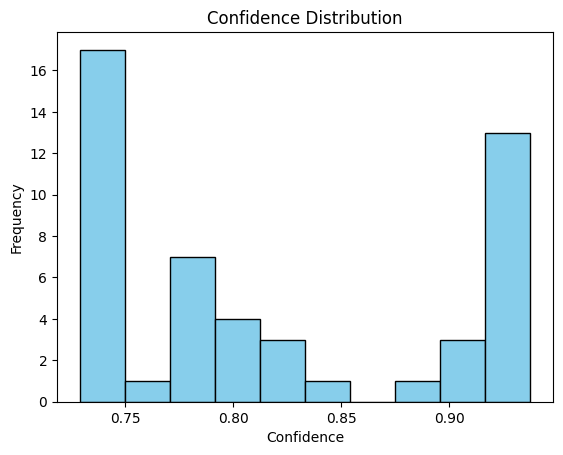

In [4]:
plt.hist(confidences, bins=10, color='skyblue', edgecolor='black')
plt.title("Confidence Distribution")
plt.xlabel("Confidence")
plt.ylabel("Frequency")
plt.show()

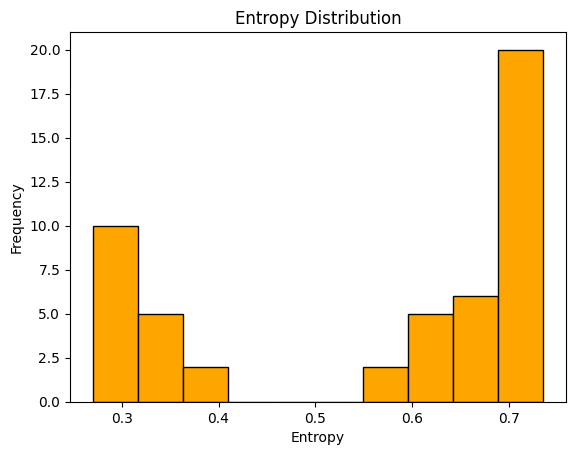

In [5]:
plt.hist(entropies, bins=10, color='orange', edgecolor='black')
plt.title("Entropy Distribution")
plt.xlabel("Entropy")
plt.ylabel("Frequency")
plt.show()

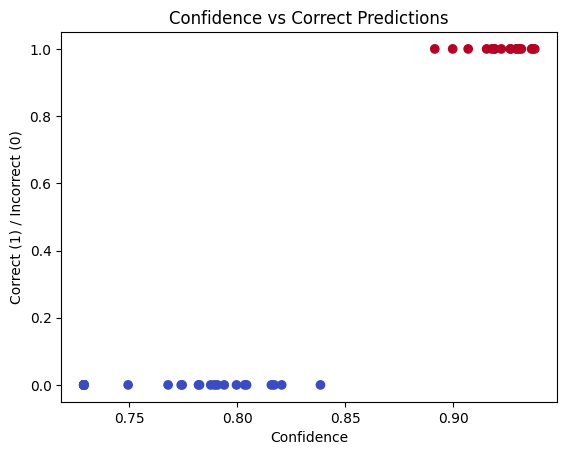

In [6]:
correct = np.array(true_labels) == np.array(pred_labels)

plt.scatter(confidences, correct, c=correct, cmap='coolwarm')
plt.title("Confidence vs Correct Predictions")
plt.xlabel("Confidence")
plt.ylabel("Correct (1) / Incorrect (0)")
plt.show()

In [7]:
def compute_ece(confidences, correct, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0
    
    for i in range(n_bins):
        low, high = bins[i], bins[i+1]
        mask = (confidences >= low) & (confidences < high)
        if np.sum(mask) > 0:
            bin_acc = np.mean(correct[mask])
            bin_conf = np.mean(confidences[mask])
            ece += np.abs(bin_conf - bin_acc) * np.sum(mask) / len(confidences)
    return ece

correct = np.array(true_labels) == np.array(pred_labels)
ece = compute_ece(confidences, correct)

ece

np.float64(0.5211828136444092)

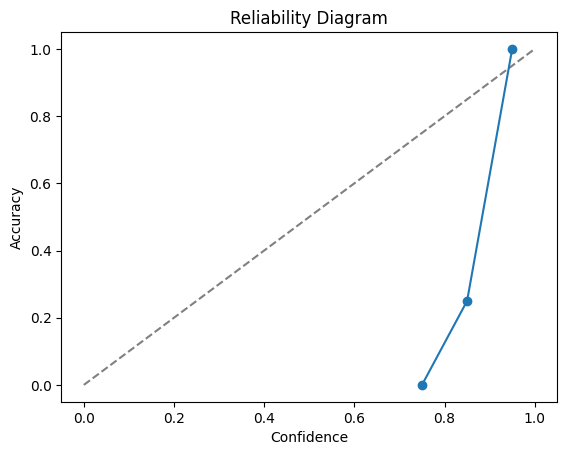

In [8]:
bins = np.linspace(0, 1, 11)
bin_centers = (bins[:-1] + bins[1:]) / 2
accs = []
confs = []

for i in range(10):
    mask = (confidences >= bins[i]) & (confidences < bins[i+1])
    if np.sum(mask) > 0:
        accs.append(np.mean(correct[mask]))
        confs.append(np.mean(confidences[mask]))
    else:
        accs.append(np.nan)
        confs.append(np.nan)

plt.plot([0, 1], [0, 1], '--', color='gray')
plt.plot(bin_centers, accs, marker='o')
plt.title("Reliability Diagram")
plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.show()